## Modèle LSTM

Dans ce notebook, nous allons implémenter un modèle de réseau de neurones récurrent basé sur des LSTM (Long Short-Term Memory) pour prédire les prix futurs d'une série temporelle.

En pratique, pour vous cela vous permettra d'avoir un modèle basé sur des réseaux de neurones récurrents, qui sont particulièrement adaptés pour les données séquentielles comme les séries temporelles.

Et pour utiliser votre modèle, donc faire une prédiction, il vous suffira de lui fournir une séquence de prix passés, et il vous donnera la prédiction du prix suivant. Par exemple :

```python
pred = model.predict([115, 116, 117, 118, 119]) 
print("Prix prédit :", pred)
```

Le plan du notebook est le suivant :
1. chargement des bibliothèques nécessaires
2. définition de la classe LSTMPricePredictor
3. chargement des données
4. entraînement du modèle
5. évaluation du modèle

## Chargement des bibliothèques nécessaires


In [60]:
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

%run -i "../BaseLoader.ipynb"


## La classe LSTMPricePredictor

Attention, cette classe est paramètrée avec les valeurs suivantes :
- la longueur des séquences d'entrée, pour l'apprentissage, et pour la prédiction (`seq_len=10` par défaut). Cela implique que le modèle va lire des séries de 10 prix pour prédire le prix suivant.
- le nombre de couches LSTM, et le nombre d'unités par couche. Le paramètre `layers_config=[50, 50]` signifie que le modèle aura deux couches LSTM, chacune avec 50 unités.
- le paramètre `lr` qui définit le taux d'apprentissage pour l'optimiseur Adam, sert à contrôler la vitesse à laquelle le modèle ajuste ses poids pendant l'entraînement. Pas besoin d'y toucher pour l'instant.

Il vous revient de déterminer si ces paramètres conviennent à votre problème, ou s'il faut les ajuster. Et cela peut être fait seulement par essais et erreurs.


In [57]:

class LSTMPricePredictor:
    def __init__(self, layers_config, seq_len=10, lr=0.001):
        """
        layers_config : liste du nombre de neurones par couche LSTM, ex: [64, 32]
        seq_len : longueur de la fenêtre temporelle (nombre de prix utilisés pour prédire le suivant)
        lr : taux d’apprentissage
        """
        self.layers_config = layers_config
        self.seq_len = seq_len
        self.lr = lr
        self.model = None
        self.scaler = MinMaxScaler()

    def prepare_data(self, prices, scaler=True):
        """
        Transforme une série de prix en séquences (X, y)
        """
        prices = np.array(prices).reshape(-1, 1)

        if scaler:
            prices_scaled = self.scaler.fit_transform(prices)
        else:
            prices_scaled = prices
            
        X, y = [], []
        for i in range(len(prices_scaled) - self.seq_len):
            X.append(prices_scaled[i:i + self.seq_len])
            y.append(prices_scaled[i + self.seq_len])
        X, y = np.array(X), np.array(y)
        return X, y

    def build_model(self):
        """
        Construit dynamiquement le modèle LSTM
        """
        model = tf.keras.models.Sequential()
        for i, units in enumerate(self.layers_config):
            return_sequences = (i < len(self.layers_config) - 1)
            if i == 0:
                model.add(tf.keras.layers.LSTM(units, return_sequences=return_sequences,
                               input_shape=(self.seq_len, 1)))
            else:
                model.add(tf.keras.layers.LSTM(units, return_sequences=return_sequences))
        model.add(tf.keras.layers.Dense(1))  # sortie : un seul prix prédit
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=self.lr), loss='mse')
        self.model = model

    def fit(self, prices, epochs=50, batch_size=16, verbose=1):
        """
        Entraîne le modèle sur la série de prix
        """
        X, y = self.prepare_data(prices)
        if self.model is None:
            self.build_model()
        self.model.fit(X, y, epochs=epochs, batch_size=batch_size, verbose=verbose)

    def predict(self, recent_prices):
        """
        Prédit le prochain prix à partir d'une sous-liste de prix récents
        """
        assert len(recent_prices) == self.seq_len, "La séquence doit avoir la même longueur que seq_len"
        seq = np.array(recent_prices).reshape(-1, 1)
        seq_scaled = self.scaler.transform(seq)
        seq_scaled = seq_scaled.reshape(1, self.seq_len, 1)
        pred_scaled = self.model.predict(seq_scaled, verbose=0)
        pred = self.scaler.inverse_transform(pred_scaled)
        return float(pred[0][0])


## Chargement de la série temporelle

In [6]:
loader = Loader(dataDefaultPath='..', debug=True)

df = loader.get(Loader.GOOGLE_FINANCE, Loader.ETF_ISHARE_MSCI_CORE_MSCI_WORLD)

df.head()

init loader: .. True
path ===== ..\data\GoogleFinance\GoogleFinance-ETFisharesCoreMSCIWorld.csv  &  ..
GoogleFinance [ ETFisharesCoreMSCIWorld ]  charged


,High,Low,Open,Close,Volume
Date,,,,,
2009-10-12,25.14,25.14,25.14,25.33,1075
2009-10-20,25.86,25.86,25.86,25.68,2000
2009-11-04,24.80,24.80,24.80,24.76,47872
2009-12-18,25.45,25.45,25.45,25.21,1675
2010-02-19,25.05,25.05,25.05,25.17,2700


In [8]:
serie = df['Close']

serie.head()

Date
2009-10-12    25.33
2009-10-20    25.68
2009-11-04    24.76
2009-12-18    25.21
2010-02-19    25.17
Name: Close, dtype: float64

In [12]:
serieLearning = serie[:int(len(serie)*0.8)]
serieTesting = serie[int(len(serie)*0.8):]

## Apprentissage du modèle LSTM

In [58]:
lstmPricePredictor = LSTMPricePredictor(layers_config=[64, 32], seq_len=10, lr=0.001)

lstmPricePredictor.fit(serieLearning, epochs=100, batch_size=16, verbose=1)

Epoch 1/100
173/173 [==============================] - 3s 5ms/step - loss: 0.0074
Epoch 2/100
173/173 [==============================] - 1s 4ms/step - loss: 4.8781e-04
Epoch 3/100
173/173 [==============================] - 1s 5ms/step - loss: 4.9158e-04
Epoch 4/100
173/173 [==============================] - 1s 5ms/step - loss: 4.8186e-04
Epoch 5/100
173/173 [==============================] - 1s 5ms/step - loss: 4.8888e-04
Epoch 6/100
173/173 [==============================] - 1s 5ms/step - loss: 4.6627e-04
Epoch 7/100
173/173 [==============================] - 1s 5ms/step - loss: 4.5558e-04
Epoch 8/100
173/173 [==============================] - 1s 5ms/step - loss: 4.4585e-04
Epoch 9/100
173/173 [==============================] - 1s 5ms/step - loss: 4.0260e-04
Epoch 10/100
173/173 [==============================] - 1s 5ms/step - loss: 4.0857e-04
Epoch 11/100
173/173 [==============================] - 1s 5ms/step - loss: 3.7858e-04
Epoch 12/100
173/173 [==============================] - 

## Prédiction avec le modèle LSTM

La première étape est de préparer les donnérs de test en séquences, comme pour l'apprentissage : on découpe la série de test en séquence de longueur `seq_len`, et on crée pour chaque une séquence des vraies prix correspondants.

In [61]:
# decoupage des données de test en séquences
X_test, y_test = lstmPricePredictor.prepare_data(serieTesting, scaler=False)

# X_test[0] est bien une séquence de seq_len prix
X_test[0]

array([[76.52],
       [76.96],
       [77.04],
       [76.75],
       [75.44],
       [76.32],
       [77.63],
       [77.56],
       [77.01],
       [77.7 ]])

Ensuite, nous pouvons prédire le prix à partir de la première séquence de test, et comparer avec le vrai prix.

In [62]:
predictions = lstmPricePredictor.predict(X_test[0])

print("Le modèle prédit", predictions, ".")
print("Mais la valeur réelle est ", y_test[0], ".")
print("Donc l'erreur au carré est de ", (predictions - y_test[0])**2, ".")

Le modèle prédit 77.52108764648438 .
Mais la valeur réelle est  [78.45] .
Donc l'erreur au carré est de  [0.86287816] .


Puis, nous pouvons faire des prédictions sur toute la série de test, et comparer les prix prédits avec les vrais prix.

In [65]:
predictions = []
errors = []
for i in range(1, len(X_test)):
    prediction = lstmPricePredictor.predict(X_test[i])
    predictions.append(prediction)
    errors.append((prediction - y_test[i])**2)  

Et enfin, nous pouvons visualiser l'erreurs moyenne quadratique (RMSE) entre les prix prédits et les vrais prix.

In [66]:
print("L'erreur moyenne des prédictions est de ", np.mean(errors), ".")

L'erreur moyenne des prédictions est de  11.910221889473112 .


Et pourquoi pas, afficher un graphique des prix prédis et des vrais prix.


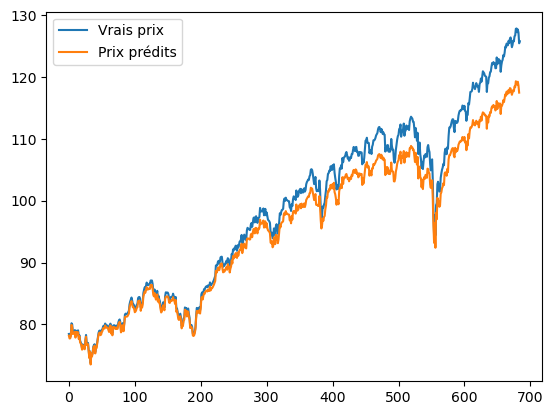

In [67]:

plt.plot(y_test, label='Vrais prix')
plt.plot(predictions, label='Prix prédits')
plt.legend()